# Klasifikasi Citra UC Merced Land Use dengan CNN (PyTorch)

Notebook ini berisi:
1. **Download & ekstraksi dataset** UC Merced Land Use (21 kelas, 100 citra per kelas).
2. **Pelatihan arsitektur VGG16** (transfer learning dari ImageNet).
3. **Pelatihan arsitektur lain**: **AlexNet** dan **MobileNetV2**.
4. **Perbandingan** akurasi, waktu latih, dan jumlah parameter.

> Disarankan dijalankan di Google Colab / mesin dengan GPU (Runtime → Change runtime type → GPU).

## 0. Instalasi & Import

In [2]:
!pip install -q wget scikit-learn matplotlib seaborn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import copy
import random
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import wget
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


## 1. Download & Ekstraksi Dataset

In [4]:
url = "https://mymldatasets.s3.eu-de.cloud-object-storage.appdomain.cloud/UCMerced_LandUse.zip"

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
zip_path = data_dir / "UCMerced_LandUse.zip"

if not zip_path.exists():
    wget.download(url, out=str(zip_path))

# Ekstraksi aman (mencegah path traversal / zip-slip)
with zipfile.ZipFile(zip_path) as arsip:
    for nama in arsip.namelist():
        tujuan = (data_dir / nama).resolve()
        if not tujuan.is_relative_to(data_dir.resolve()):
            raise ValueError("Lokasi file ZIP tidak valid")
    arsip.extractall(data_dir)

# Cari folder 'Images' (struktur ZIP bisa berbeda: data/dataset/Images atau data/UCMerced_LandUse/Images)
kandidat = data_dir / "dataset" / "Images"
if kandidat.exists():
    image_dir = kandidat
else:
    image_dir = next(p for p in data_dir.rglob("Images") if p.is_dir())

print("\nFolder gambar :", image_dir)


Folder gambar : data/dataset/Images


## 2. Eksplorasi Dataset

Jumlah kelas: 21
count     21.0
min      100.0
max      100.0
dtype: float64


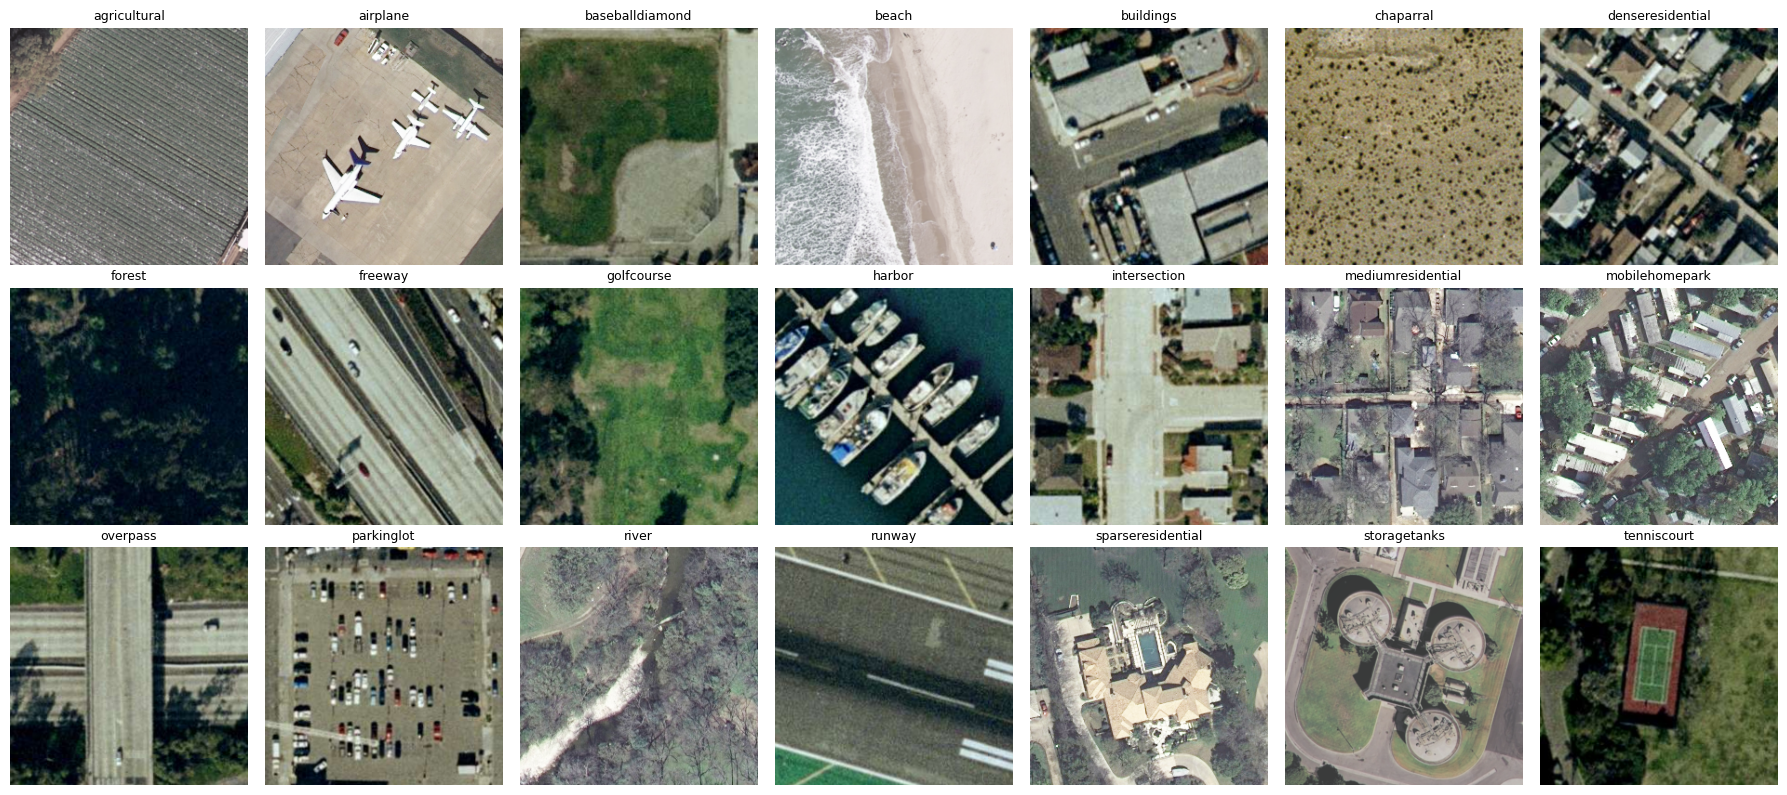

In [5]:
kelas = sorted([d.name for d in image_dir.iterdir() if d.is_dir()])
print("Jumlah kelas:", len(kelas))
jumlah = {k: len(list((image_dir / k).glob("*"))) for k in kelas}
print(pd.Series(jumlah).describe()[["count", "min", "max"]])

# Tampilkan 1 contoh per kelas
fig, axes = plt.subplots(3, 7, figsize=(18, 8))
for ax, k in zip(axes.ravel(), kelas):
    img_path = sorted((image_dir / k).glob("*"))[0]
    ax.imshow(Image.open(img_path).convert("RGB"))
    ax.set_title(k, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Preprocessing & DataLoader

Pembagian data: **70% train / 15% validasi / 15% test** (stratified). Citra di-resize ke 224×224 dan dinormalisasi dengan statistik ImageNet (karena memakai bobot pretrained).

In [6]:
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# Dua ImageFolder dengan transform berbeda, indeks yang sama
full_train = datasets.ImageFolder(image_dir, transform=train_tf)
full_eval = datasets.ImageFolder(image_dir, transform=eval_tf)
class_names = full_train.classes
num_classes = len(class_names)
targets = np.array(full_train.targets)

idx = np.arange(len(targets))
idx_train, idx_temp = train_test_split(idx, test_size=0.30, stratify=targets, random_state=SEED)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=targets[idx_temp], random_state=SEED)

train_ds = Subset(full_train, idx_train)
val_ds = Subset(full_eval, idx_val)
test_ds = Subset(full_eval, idx_test)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)} | Kelas: {num_classes}")

Train: 1470 | Val: 315 | Test: 315 | Kelas: 21


## 4. Fungsi Bantu (Model, Training, Evaluasi)

In [7]:
def build_model(name, num_classes, freeze_backbone=False):
    """Bangun model pretrained ImageNet dan ganti layer klasifikasi terakhir."""
    if name == "vgg16":
        model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)
    elif name == "alexnet":
        model = models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1)
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)
    elif name == "mobilenet_v2":
        model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    else:
        raise ValueError(f"Model tidak dikenal: {name}")

    if freeze_backbone:  # hanya latih classifier
        for p in model.features.parameters():
            p.requires_grad = False
    return model.to(device)


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    loss_sum, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            loss_sum += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return loss_sum / n, correct / n


def train_model(name, epochs=10, lr=1e-4, freeze_backbone=False):
    model = build_model(name, num_classes, freeze_backbone)
    total, trainable = count_params(model)
    print(f"[{name}] parameter total: {total:,} | dilatih: {trainable:,}")

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc, best_state = 0.0, None
    start = time.time()

    for ep in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        scheduler.step()
        for k, v in zip(history, [tl, vl, ta, va]):
            history[k].append(v)
        if va > best_acc:
            best_acc, best_state = va, copy.deepcopy(model.state_dict())
        print(f"Epoch {ep:02d}/{epochs} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")

    elapsed = time.time() - start
    model.load_state_dict(best_state)
    print(f"Selesai dalam {elapsed/60:.1f} menit | best val acc: {best_acc:.4f}")
    return model, history, {"model": name, "params_total": total, "params_trainable": trainable,
                            "train_time_s": elapsed, "best_val_acc": best_acc}


def plot_history(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
    ax[0].set_title(f"{title} - Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(history["train_acc"], label="train"); ax[1].plot(history["val_acc"], label="val")
    ax[1].set_title(f"{title} - Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    preds, labels = [], []
    for x, y in loader:
        out = model(x.to(device))
        preds.extend(out.argmax(1).cpu().numpy())
        labels.extend(y.numpy())
    return np.array(labels), np.array(preds)


def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(13, 11))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion Matrix - {title}")
    plt.xlabel("Prediksi"); plt.ylabel("Aktual")
    plt.xticks(rotation=90); plt.tight_layout(); plt.show()


results = []

## 5. Soal 1 — Melatih dengan Arsitektur **VGG16**

VGG16 sangat besar (~134 juta parameter). Agar pelatihan cepat, secara default hanya bagian *classifier* yang dilatih (`freeze_backbone=True`). Ubah ke `False` untuk *fine-tuning* penuh (lebih akurat, tetapi lebih lambat dan butuh memori GPU lebih besar).

In [ ]:
vgg_model, vgg_hist, vgg_info = train_model("vgg16", epochs=10, lr=1e-4, freeze_backbone=True)
plot_history(vgg_hist, "VGG16")

[vgg16] parameter total: 134,346,581 | dilatih: 119,631,893


In [ ]:
y_true, y_pred = evaluate(vgg_model, test_loader)
test_acc = (y_true == y_pred).mean()
vgg_info["test_acc"] = test_acc
results.append(vgg_info)
print(f"Test accuracy VGG16: {test_acc:.4f}\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
plot_confusion(y_true, y_pred, "VGG16")

## 6. Soal 2 — Melatih dengan Arsitektur Lain

### 6a. AlexNet

In [ ]:
alex_model, alex_hist, alex_info = train_model("alexnet", epochs=10, lr=1e-4, freeze_backbone=False)
plot_history(alex_hist, "AlexNet")

y_true, y_pred = evaluate(alex_model, test_loader)
test_acc = (y_true == y_pred).mean()
alex_info["test_acc"] = test_acc
results.append(alex_info)
print(f"Test accuracy AlexNet: {test_acc:.4f}\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
plot_confusion(y_true, y_pred, "AlexNet")

### 6b. MobileNetV2 (ringan, cocok untuk perangkat dengan sumber daya terbatas)

In [ ]:
mob_model, mob_hist, mob_info = train_model("mobilenet_v2", epochs=10, lr=1e-4, freeze_backbone=False)
plot_history(mob_hist, "MobileNetV2")

y_true, y_pred = evaluate(mob_model, test_loader)
test_acc = (y_true == y_pred).mean()
mob_info["test_acc"] = test_acc
results.append(mob_info)
print(f"Test accuracy MobileNetV2: {test_acc:.4f}\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
plot_confusion(y_true, y_pred, "MobileNetV2")

## 7. Perbandingan Model

In [ ]:
df = pd.DataFrame(results)
df["params_total (juta)"] = (df["params_total"] / 1e6).round(2)
df["params_trainable (juta)"] = (df["params_trainable"] / 1e6).round(2)
df["train_time (menit)"] = (df["train_time_s"] / 60).round(2)
tabel = df[["model", "params_total (juta)", "params_trainable (juta)", "train_time (menit)", "best_val_acc", "test_acc"]]
display(tabel.style.format({"best_val_acc": "{:.4f}", "test_acc": "{:.4f}"}))

tabel.set_index("model")[["best_val_acc", "test_acc"]].plot(kind="bar", figsize=(7, 4), ylim=(0, 1.05))
plt.title("Perbandingan Akurasi"); plt.ylabel("Accuracy"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## 8. Simpan Model

In [ ]:
out = Path("models"); out.mkdir(exist_ok=True)
torch.save(vgg_model.state_dict(), out / "vgg16_ucmerced.pth")
torch.save(alex_model.state_dict(), out / "alexnet_ucmerced.pth")
torch.save(mob_model.state_dict(), out / "mobilenetv2_ucmerced.pth")
print("Model tersimpan di:", out.resolve())

## Catatan
- Jumlah epoch, learning rate, dan opsi `freeze_backbone` dapat diubah di setiap pemanggilan `train_model(...)`.
- Untuk arsitektur lain, tambahkan cabang baru pada fungsi `build_model` (misalnya `resnet18`, `densenet121`, `efficientnet_b0`).
- Hasil akurasi akan bervariasi tergantung seed, jumlah epoch, dan perangkat keras.